# 9b. Additions: Iterables, and Changing a List in a Loop

Additions to [Chapter 9: Lists](https://y-rosenthal.github.io/yrThinkPython/chap09.html): a review of the
**iterables** that a `for` loop can go through, and a rule that you must never break: **do not change a list
in the body of a loop that goes through that list**. A list is the first iterable in the book that a program
can change, and the page shows what goes wrong when a loop changes it. Read this page after the chapter.
The practice questions at the end have answers: try each question first, then open its **Answer**.

[Run this page on Colab](https://colab.research.google.com/github/y-rosenthal/yrThinkPython/blob/v3/yr/chap09_additions_iterables.ipynb)

Run the setup cell below first. In Colab, it downloads the file `tiny_book.txt` (a small "book" of 4 lines
that this page reads), and `thinkpython.py`, which lets this page show the errors of some examples without
stopping the page.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/ThinkPython/raw/v3/thinkpython.py');
download('https://y-rosenthal.github.io/yrThinkPython/tiny_book.txt');
download('https://github.com/AllenDowney/ThinkPython/raw/v3/diagram.py');
download('https://y-rosenthal.github.io/yrThinkPython/yrdiagram.py');

import thinkpython

## Review: what is an iterable?

An **iterable** is a value that a `for` loop can go through, one item at a time:

```python
for VARIABLE in ITERABLE:
    BODY
```

These are the iterables of the book up to Chapter 9:

| Iterable | What the loop variable gets | Where the book teaches it |
|---|---|---|
| a range, such as `range(3)` | the numbers of the range | Chapter 3, and "3b. Additions: The Three Forms of range" |
| a string, such as `'cat'` | each character of the string | Chapter 7 |
| a file object, from `open(PATH)` | each line of the file, as a string with a newline at the end | Chapter 7, and "7c. Additions: File Paths and for Loops" |
| `reversed(ITERABLE)` | the items of another iterable, in the opposite order | "7c. Additions: File Paths and for Loops" |
| a list, such as `[10, 20, 30]` | each item of the list | Chapter 9 |

Later chapters add more: a dictionary (Chapter 10) gives its keys, and a tuple (Chapter 11) gives its items.
A number is not an iterable: `for x in 5:` raises a `TypeError`.

**A range** gives numbers:

In [2]:
for number in range(1, 4):
    print(number)

1
2
3


**A string** gives its characters:

In [3]:
for letter in 'cat':
    print(letter)

c
a
t


**A file object** gives the lines of the file. This page uses the small file `tiny_book.txt`, which has 4
lines. In Colab, the setup cell downloaded it. To run the code on your own computer, download the file:
[tiny_book.txt](https://y-rosenthal.github.io/yrThinkPython/tiny_book.txt) (right-click the link and choose to save it), and give `open` its path
("7c. Additions: File Paths and for Loops"). `strip` removes the newline at the end of each line:

In [4]:
for line in open('tiny_book.txt'):
    print(line.strip())

Once upon a time, a little fox lived at the edge of a forest.
Every morning, the fox ran down to the river to drink.
One day, the fox met a turtle who could not cross the river.
The fox carried the turtle across, and they lived happily ever after.


**A list** gives its items:

In [5]:
for word in ['apple', 'banana', 'cherry']:
    print(word, len(word))

apple 5
banana 6
cherry 6


## Lists are mutable: `y = x` and a copy

Chapter 9 says that lists are **mutable** ("Lists are mutable"): a program can change a list after it makes
it. This matters when two variables refer to the same list ("Aliasing" in Chapter 9). Make a list `x`, a
second variable `y` with `y = x`, and a third variable `z` with `z = list(x)`. `list(x)` makes a **copy**: a new
list with the same items (Chapter 9; `x[:]` makes a copy too).

In [6]:
x = ['apple', 'pear', 'plum']
y = x
z = list(x)
print(x is y, x is z, x == z)

True False True


`x is y` is `True`: `y = x` does not make a new list, so `x` and `y` refer to the **same** list. `x is z` is
`False`: `z` refers to a different list. `x == z` is `True`: the two lists have the same items. The state
diagram shows it:

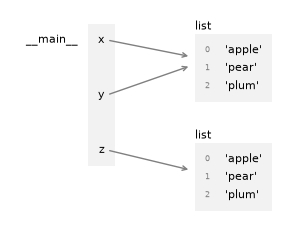

In [7]:
# @title State diagram: x and y refer to one list, z to a copy
from yrdiagram import draw_variables

x = ['apple', 'pear', 'plum']
y = x
z = list(x)
draw_variables({'x': x, 'y': y, 'z': z})

**How to read the diagram.** It uses the notation of the book's state diagrams and stack diagrams (Chapters 2,
3 and 9). The gray box on the left is the frame `__main__`: it holds the variables. Each arrow goes from a
variable to the **object** that it refers to. Two arrows that end at the same object mean that the two
variables refer to the same object. The diagram is drawn from the real variables: it runs the code above, and
uses `is` to find which variables refer to the same object.

**Now change the list through `y`.** `append` changes the list that `y` refers to:

In [8]:
x = ['apple', 'pear', 'plum']
y = x
z = list(x)
y.append('kiwi')
print('x:', x)
print('y:', y)
print('z:', z)

x: ['apple', 'pear', 'plum', 'kiwi']
y: ['apple', 'pear', 'plum', 'kiwi']
z: ['apple', 'pear', 'plum']


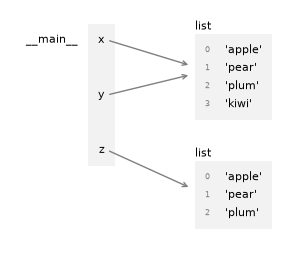

In [9]:
# @title State diagram: after y.append('kiwi')
from yrdiagram import draw_variables

x = ['apple', 'pear', 'plum']
y = x
z = list(x)
y.append('kiwi')
draw_variables({'x': x, 'y': y, 'z': z})

`x` shows the change too, though the code never used `x`. There is only one list for `x` and `y`, and
`append` changed it. `z` refers to its own list, so it does not change.

Compare this with a string ("8b. Additions: String Methods", "Strings are immutable"): a program cannot change
a string, so `str(x)` does not even make a copy, and a change "through `y`" is always an assignment of a new
string to `y`.

| | `y = x` | a copy: `z = list(x)`, `z = str(x)` | `y` changes |
|---|---|---|---|
| **mutable** (list, dictionary) | `y` refers to the same object | `z` refers to a new object | `x` shows the change, `z` does not |
| **immutable** (string, number, tuple, range) | `y` refers to the same object | `z` refers to the same object (no copy is needed) | not possible: `y = ...` makes `y` refer to a new object, and `x` and `z` do not change |

**When you need a list that does not change when another variable changes, make a copy:** `list(x)` or
`x[:]`. A function that gets a list from its caller and must not change it can work on a copy, or make a new
list (see "The right way" below).

## Changing a list in a loop over the list

Chapter 9 shows that lists are **mutable**: a program can change a list after it makes it. The method
`append` adds an item at the end of a list, and the method `remove` takes an item out. This section shows
what happens when the body of a loop changes the list that the loop goes through.

**The task:** write a function called `remove_evens` that takes a list of numbers, removes the even numbers,
and returns the list with the numbers that are left. Here is a first try. **It is wrong:**

In [10]:
def remove_evens(numbers):
    for n in numbers:
        if n % 2 == 0:
            numbers.remove(n)
    return numbers

remove_evens([11, 22, 33, 44, 55, 66])

[11, 33, 55]

The result is right: the even numbers 2, 4 and 6 are gone. But the function has a bug. Try it with other
lists:

In [11]:
def remove_evens(numbers):
    for n in numbers:
        if n % 2 == 0:
            numbers.remove(n)
    return numbers

print(remove_evens([12, 24, 36, 48]))
print(remove_evens([11, 22, 24, 35]))

[24, 48]
[11, 24, 35]


The results should be `[]` and `[11, 35]`. The function left `24` and `48` in the first list, and `24` in
the second. There is no error message: the function just returns a wrong list. A bug like this is hard to find,
because a test with one list (the first one above) can pass while the code is wrong.

To see what happens, display each value that the loop gives to `n`:

In [12]:
numbers = [12, 24, 36, 48]
for n in numbers:
    print('n is', n, 'and the list is', numbers)
    if n % 2 == 0:
        numbers.remove(n)
print('After the loop:', numbers)

n is 12 and the list is [12, 24, 36, 48]
n is 36 and the list is [24, 36, 48]
After the loop: [24, 48]


The loop never gives `24` or `48` to `n`. Step by step:

| Iteration | Position that the loop reads | `n` | The list after `remove` |
|---|---|---|---|
| 1 | 0 | `12` | `[24, 36, 48]`: every item moved one position to the left |
| 2 | 1 | `36` (not `24`: `24` is now at position 0) | `[24, 48]` |
| 3 | 2 | the list has no position 2, so the loop ends | `[24, 48]` |

Each `remove` moves the items after it one position to the left, so the loop skips the item right after
each item that it removes. With `[11, 22, 33, 44, 55, 66]`, no two even numbers are next to each other, so the
skipped items were odd numbers, and the result was right by chance.

**Adding items is worse.** In this loop, each iteration adds an item at the end of the list. The loop never
gets to the end of the list, so **the loop never ends**:

```python
numbers = [100, 200, 300]
for n in numbers:
    numbers.append(n)    # never do this: an infinite loop
```

This code is text, not a code cell, so it cannot run. If you run such a loop, stop it: in Colab, click
**Runtime**, then **Interrupt execution**; in Thonny, click the red **Stop** button.

## Why the bug happens: a list is an iterable that can change

A `for` loop over a list does **not** make a copy of the list when it starts. It goes through the list itself,
by position:

1. The loop starts at position 0.
2. If the position is less than the length that the list has **now**, the loop assigns the item at that
   position to the loop variable and runs the body. Otherwise the loop ends.
3. The loop adds 1 to the position, and goes back to step 2.

So when the body changes the list, the loop goes on through the **changed** list:

- When the body removes an item, the items after it move one position to the left, and the loop skips one
  item.
- When the body adds an item, the list gets longer, and the loop gets to the new item too. A loop that adds an
  item in each iteration never ends.
- When the body assigns a new value to an item that the loop has not got to yet (for example,
  `numbers[3] = 0`), the loop gets the new value, not the old one.

**The rule:** in the body of a `for` loop that goes through a list, **never change that list**: do not add,
remove or replace its items. Code that does this is **very bad code**. It can skip items without an error
message, or never end, and a reader cannot see what it does without following each step. Never write such
code.

The function also has a second problem: it changes the list that the caller gave it, because the parameter
and the caller's variable refer to the same list ("List arguments" in Chapter 9).

**The right way:** make a **new** list, and append to it the items to keep. The loop goes through one list,
and the body changes another list:

In [13]:
def remove_evens(numbers):
    result = []
    for n in numbers:
        if n % 2 != 0:
            result.append(n)
    return result

print(remove_evens([11, 22, 33, 44, 55, 66]))
print(remove_evens([12, 24, 36, 48]))
print(remove_evens([11, 22, 24, 35]))

[11, 33, 55]
[]
[11, 35]


All three results are right, and the caller's lists do not change.

## An immutable iterable: a string

Strings are **immutable** ("Strings are immutable" in Chapter 8): no method or operator can change a string.
An expression such as `word + '!'` or `word.upper()` makes a **new** string. So the body of a loop over a
string cannot change the string that the loop goes through. Even this loop, which seems to make its string
longer, runs exactly 3 times:

In [14]:
word = 'cat'
for letter in word:
    word = word + letter
    print(letter, word)
print('After the loop:', word)

c catc
a catca
t catcat
After the loop: catcat


At the start, the loop gets the string `'cat'` that `word` refers to, and it goes through that string. The
assignment `word = word + letter` makes a new string and makes the **variable** `word` refer to it. The string
`'cat'` does not change, so the loop goes through its 3 characters and ends. A variable and the value that it
refers to are different things ("Objects and values" in Chapter 9).

The same is true for the other immutable iterables: a range, and a tuple (Chapter 11).

**The difference is between changing a value and assigning a new value to a variable.** A list can show both:

In [15]:
numbers = [100, 200, 300]
for n in numbers:
    numbers = numbers + [n * 10]
print(numbers)

[100, 200, 300, 1000, 2000, 3000]


This loop runs 3 times and ends. The `+` operator makes a **new** list, and the assignment makes the variable
`numbers` refer to it. The list that the loop goes through, `[100, 200, 300]`, does not change. `numbers.append(n * 10)`
would change that list itself, and the loop would never end.

So with an immutable iterable, the body cannot change what the loop goes through. Code like the two loops
above is still bad code: a reader must know the difference between changing a value and assigning a new value
to a variable, to see how many times the loop runs. Use a different variable for the result (for example,
`longer = longer + letter`), and keep the loop's iterable as it is.

## Practice questions

### Question 1 (easy): which are iterables?

Which of these values can follow `in` in the header of a `for` loop?

`range(5)`, `'hello'`, `42`, `[30, 10, 20]`, `open('tiny_book.txt')`, `3.5`, `reversed('abc')`

:::{admonition} Answer
:class: dropdown

`range(5)`, `'hello'`, `[30, 10, 20]`, `open('tiny_book.txt')` and `reversed('abc')` are iterables. `42` and `3.5`
are numbers, not iterables: `for x in 42:` raises `TypeError: 'int' object is not iterable`.
:::


### Question 2 (easy): what is displayed?

Predict what this code displays. Then run the cell to check (on the website, click **Show code cell output**).

In [16]:
count = 0
for line in open('tiny_book.txt'):
    if 'the fox' in line.lower():
        count = count + 1
print(count)

3


:::{admonition} Answer
:class: dropdown

```
3
```

The loop gets the 4 lines of `tiny_book.txt`. Three of them have the text `the fox`: the second line
(`... the fox ran ...`), the third line (`... the fox met ...`) and the fourth line, which starts with
`The fox`: `lower` makes it `the fox`. The first line has `a little fox`, not `the fox`.
:::


### Question 3 (medium): what is displayed?

This is the wrong `remove_evens` from the page. Predict what this code displays. Then run the cell to check
(on the website, click **Show code cell output**).

In [17]:
def remove_evens(numbers):
    for n in numbers:
        if n % 2 == 0:
            numbers.remove(n)
    return numbers

print(remove_evens([13, 26, 28, 39, 40, 52]))

[13, 28, 39, 52]


:::{admonition} Answer
:class: dropdown

```
[13, 28, 39, 52]
```

The loop reads position 1 (`26`) and removes it: `28` moves to position 1, and the loop skips it. Then it reads
position 2 (`39`), and position 3 (`40`), which it removes: `52` moves to position 3, and the loop ends because
the list has no position 4. `28` and `52` are left in the list.
:::


### Question 4 (medium): what is displayed?

Predict what this code displays. Then run the cell to check (on the website, click **Show code cell output**).

In [18]:
text = 'ab'
for ch in text:
    text = text + ch.upper()
print(text)

abAB


:::{admonition} Answer
:class: dropdown

```
abAB
```

The loop goes through the string `'ab'`, which cannot change, so it runs 2 times. Each assignment makes a new
string and assigns it to `text`: `'abA'`, then `'abAB'`.
:::


### Question 4b (medium): what is displayed?

Predict what this code displays. Then run the cell to check (on the website, click **Show code cell output**).

In [19]:
a = ['red', 'green']
b = a
c = a[:]
b.append('blue')
c.append('black')
print(a)
print(b)
print(c)

['red', 'green', 'blue']
['red', 'green', 'blue']
['red', 'green', 'black']


:::{admonition} Answer
:class: dropdown

```
['red', 'green', 'blue']
['red', 'green', 'blue']
['red', 'green', 'black']
```

`a` and `b` refer to the same list, so `b.append('blue')` changes the list of `a` too. `a[:]` makes a copy, so
`c` refers to a different list: `c.append('black')` changes only that list.
:::


### Question 5 (medium): how many times?

How many times does each loop run? Explain the difference.

```python
first = [50, 60]
for item in first:
    first = first + [item]
```

```python
second = [50, 60]
for item in second:
    second.append(item)
```

:::{admonition} Answer
:class: dropdown

The first loop runs **2 times**. `first + [item]` makes a new list, and the assignment makes `first` refer to
it. The list that the loop goes through, `[50, 60]`, does not change. After the loop, `first` is
`[50, 60, 50, 60]`.

The second loop **never ends**. `append` changes the list that the loop goes through: each iteration adds an
item, so the loop never gets to the end of the list. Both loops are bad code, and the second one is a bug.
:::


### Question 6 (hard): find the bug

This function is supposed to remove the words that are shorter than `length` from a list of words, and to
return the list with the words that are left. Find the bug, and write a correct version that does not change
the caller's list.

```python
def remove_short_words(words, length):
    for word in words:
        if len(word) < length:
            words.remove(word)
    return words
```

For example, `remove_short_words(['a', 'an', 'the', 'apple'], 3)` should return `['the', 'apple']`.

:::{admonition} Answer
:class: dropdown

The body removes items from the list that the loop goes through. Each `remove` moves the next word one
position to the left, so the loop skips it. With `['a', 'an', 'the', 'apple']`, the loop removes `'a'`, skips
`'an'`, and returns `['an', 'the', 'apple']`.

A correct version makes a new list:

```python
def remove_short_words(words, length):
    result = []
    for word in words:
        if len(word) >= length:
            result.append(word)
    return result
```

`remove_short_words(['a', 'an', 'the', 'apple'], 3)` returns `['the', 'apple']`, and the caller's list does
not change.
:::


### Question 7 (hard): write a function

Write a function called `remove_all` that takes a list and a value, and returns a **new** list with all the
items of the list except the ones equal to the value. The function must not change the list that it gets.

For example, `remove_all(['cat', 'dog', 'cat', 'cat', 'fox'], 'cat')` returns `['dog', 'fox']`, and `remove_all(['a', 'b'], 'c')` returns
`['a', 'b']`.

Start from this header (replace `...` with the body):

```python
def remove_all(items, value):
    ...
```

:::{admonition} Answer
:class: dropdown

```python
def remove_all(items, value):
    result = []
    for item in items:
        if item != value:
            result.append(item)
    return result
```

The loop goes through `items`, and the body appends to `result`, a different list. So the loop gets every
item, also the items right after a removed one, and `items` does not change.
:::


## Credits

*Additions by Prof. Y. Rosenthal, for* [Think Python: 3rd Edition](https://allendowney.github.io/ThinkPython/index.html) *by Allen B. Downey.*
*Text license:* [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)